In [1]:
# Code Cell 1: Import libraries and load dataset
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Open the Excel file and specify the sheet name shown in your Excel workbook
df = pd.read_csv("all_data_M_2023.csv")

# Display the first few rows
df.head()

C:\Users\felip\AppData\Local\Temp\ipykernel_40676\3998400045.py:2: DtypeWarning: Columns (4,13,14,15,16,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("all_data_M_2023.csv")


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.40,"29,050","35,660","48,060","76,980","121,470",NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,"54,550","78,330","116,880","169,090","231,620",NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,"46,400","66,170","103,460","165,500",#,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,"80,000","130,840","206,680",#,#,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,"80,000","130,840","206,680",#,#,NaN,NaN


In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# Load the dataset
df = pd.read_csv("all_data_M_2023.csv", low_memory=False)

# 1. Checking missing data
print("--- Missing Data Count ---")
print(
    df[
        [
            "TOT_EMP",
            "A_MEAN",
            "H_MEAN",
            "A_MEDIAN",
            "JOBS_1000",
            "LOC_QUOTIENT",
        ]
    ]
    .isnull()
    .sum()
)

# Convert numerical columns to float (handles '*' or missing values by converting them to NaN)
num_cols = [
    "TOT_EMP",
    "A_MEAN",
    "H_MEAN",
    "A_MEDIAN",
    "JOBS_1000",
    "LOC_QUOTIENT",
]
for col in num_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Drop rows missing crucial employment numbers
df_clean = df.dropna(subset=["TOT_EMP"]).copy()

# 2. Handling Outliers & Grouping
# The dataset has aggregate rows like "00-0000" (All Occupations) which have 150+ million jobs!
# These act as massive outliers when looking at individual tech jobs, so we filter for detailed roles only ('O_GROUP' == 'detailed').
# We also focus on major group 15-0000 (Computer and Mathematical Occupations).

tech_df = df_clean[
    (df_clean["O_GROUP"] == "detailed")
    & (df_clean["OCC_CODE"].str.startswith("15-"))
].copy()

print("\nFiltered Tech/AI Dataset Shape:", tech_df.shape)
tech_df[["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN"]].head()

--- Missing Data Count ---
TOT_EMP              0
A_MEAN               0
H_MEAN               0
A_MEDIAN             0
JOBS_1000       177501
LOC_QUOTIENT    177501
dtype: int64

Filtered Tech/AI Dataset Shape: (8619, 32)


,OCC_CODE,OCC_TITLE,TOT_EMP,A_MEAN
1557,15-2021,Mathematicians,750.0,NaN
2850,15-1211,Computer Systems Analysts,50.0,NaN
2852,15-1232,Computer User Support Specialists,260.0,NaN
2854,15-1244,Network and Computer Systems Administrators,80.0,NaN
2856,15-1252,Software Developers,50.0,NaN


### Visualisation 1: Horizontal Bar Chart ###
* *** Objective *** I want to compare total employment ("TOT_EMP") across different tech, AI, and software engineering job titles to see which jobs have the most workers


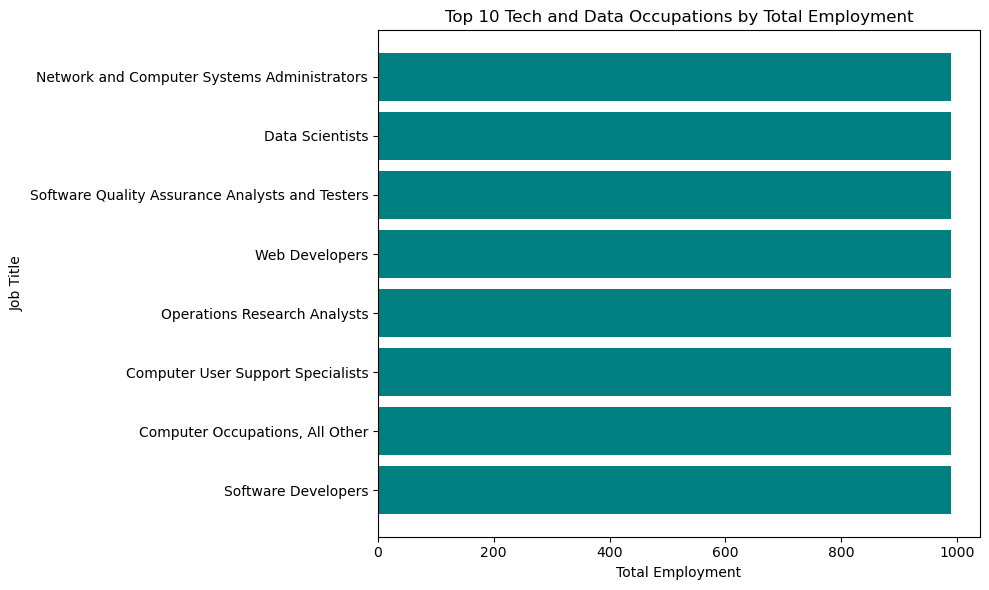

In [14]:
# Get top 10 jobs by employment size
top_jobs = tech_df.sort_values(by="TOT_EMP", ascending=True).tail(10)

plt.figure(figsize=(10, 6))
plt.barh(top_jobs["OCC_TITLE"], top_jobs["TOT_EMP"], color="teal")
plt.xlabel("Total Employment")
plt.ylabel("Job Title")
plt.title("Top 10 Tech and Data Occupations by Total Employment")
plt.tight_layout()
plt.show()